# Requirements

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:

df = pd.read_csv(r'Student_Performance.csv')


In [4]:
df.columns

Index(['Hours Studied', 'Previous Scores', 'Extracurricular Activities',
       'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index'],
      dtype='object')

# Describe data

| Feature                            | Description                                                             | Type        |
| ---------------------------------- | ----------------------------------------------------------------------- | ----------- |
| `Hours Studied`                    | Number of hours spent studying                                          | Numerical   |
| `Previous Scores`                  | Student's previous exam scores                                          | Numerical   |
| `Extracurricular Activities`       | Whether the student participates in extracurricular activities (Yes/No) | Categorical |
| `Sleep Hours`                      | Number of hours the student sleeps per day                              | Numerical   |
| `Sample Question Papers Practiced` | Number of sample question papers practiced by the student               | Numerical   |
| `Performance Index`                | Student's overall academic performance score (Target Variable)          | Numerical   |

In [ ]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1.0,91
1,4,82,No,4,2.0,65
2,8,51,Yes,7,2.0,45
3,5,52,Yes,5,2.0,36
4,7,75,No,8,5.0,66


In [ ]:
df.shape

(10000, 6)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        8428 non-null   object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  7144 non-null   float64
 5   Performance Index                 10000 non-null  int64  
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB


In [6]:
df.isnull().sum()

,0
Hours Studied,0
Previous Scores,0
Extracurricular Activities,1572
Sleep Hours,0
Sample Question Papers Practiced,2856
Performance Index,0


In [7]:
df.duplicated().sum()

np.int64(132)

In [8]:
df.drop_duplicates(inplace=True)

In [10]:
from sklearn import impute
from sklearn.impute import SimpleImputer
imputer=SimpleImputer(missing_values=np.nan,strategy='most_frequent')
df[['Extracurricular Activities']]=imputer.fit_transform(df[['Extracurricular Activities']])


(array([693., 701., 660., 738., 670., 730., 759., 725., 738., 730.]),
 array([0. , 0.9, 1.8, 2.7, 3.6, 4.5, 5.4, 6.3, 7.2, 8.1, 9. ]),
 <BarContainer object of 10 artists>)

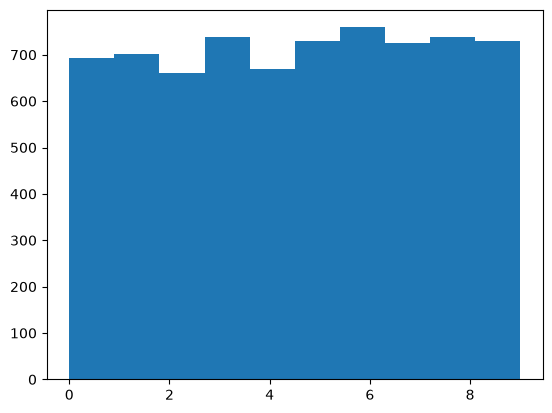

In [ ]:
plt.hist(df['Sample Question Papers Practiced'])

In [11]:
imputer=SimpleImputer(missing_values=np.nan,strategy='mean')
df[['Sample Question Papers Practiced']]=imputer.fit_transform(df[['Sample Question Papers Practiced']])

In [ ]:
df.isnull().sum().sum()

0

In [ ]:
df.duplicated().sum()

151

In [ ]:
df.drop_duplicates(inplace=True)

In [12]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df['Extracurricular Activities']=le.fit_transform(df['Extracurricular Activities'])
df.head()


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,1,9,1.0,91
1,4,82,0,4,2.0,65
2,8,51,1,7,2.0,45
3,5,52,1,5,2.0,36
4,7,75,0,8,5.0,66


<Axes: xlabel='Sample Question Papers Practiced', ylabel='Performance Index'>

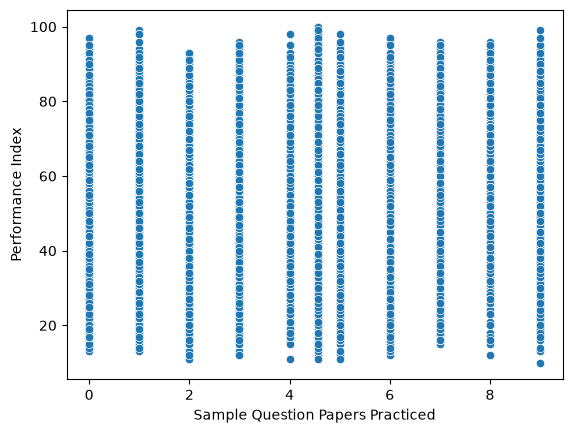

In [ ]:
sns.scatterplot(x='Sample Question Papers Practiced',y='Performance Index',data=df)

In [ ]:
df['Sample Question Papers Practiced'].corr(
    df['Performance Index']
)

0.030805500952450365

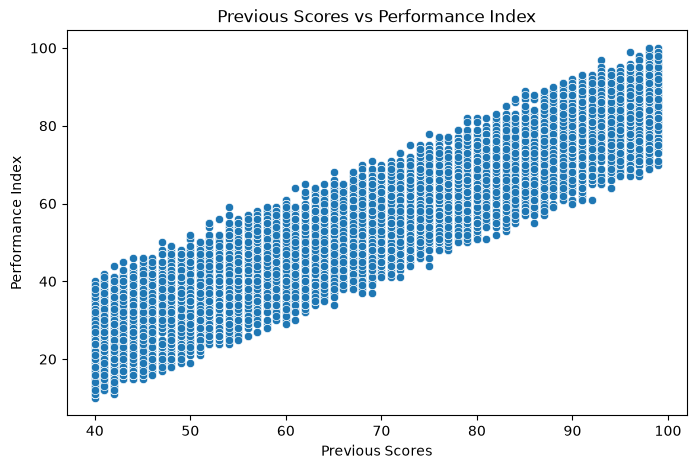

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Previous Scores', y='Performance Index', data=df)
plt.title('Previous Scores vs Performance Index')
plt.show()

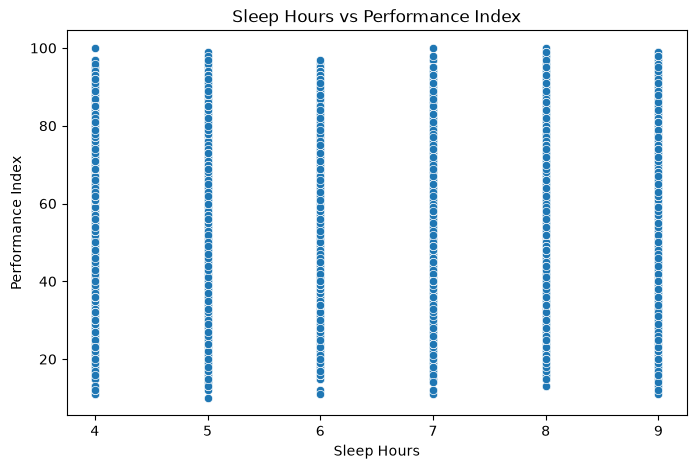

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Sleep Hours', y='Performance Index', data=df)
plt.title('Sleep Hours vs Performance Index')
plt.show()

In [13]:
from sklearn.preprocessing import MinMaxScaler
scaler=MinMaxScaler()
df[['Previous Scores']]=scaler.fit_transform(df[['Previous Scores']])
df

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,1.000000,1,9,1.0,91
1,4,0.711864,0,4,2.0,65
2,8,0.186441,1,7,2.0,45
3,5,0.203390,1,5,2.0,36
4,7,0.593220,0,8,5.0,66
...,...,...,...,...,...,...
9995,1,0.152542,1,4,2.0,23
9996,7,0.406780,1,8,5.0,58
9997,6,0.728814,1,8,5.0,74
9998,9,0.966102,1,7,0.0,95


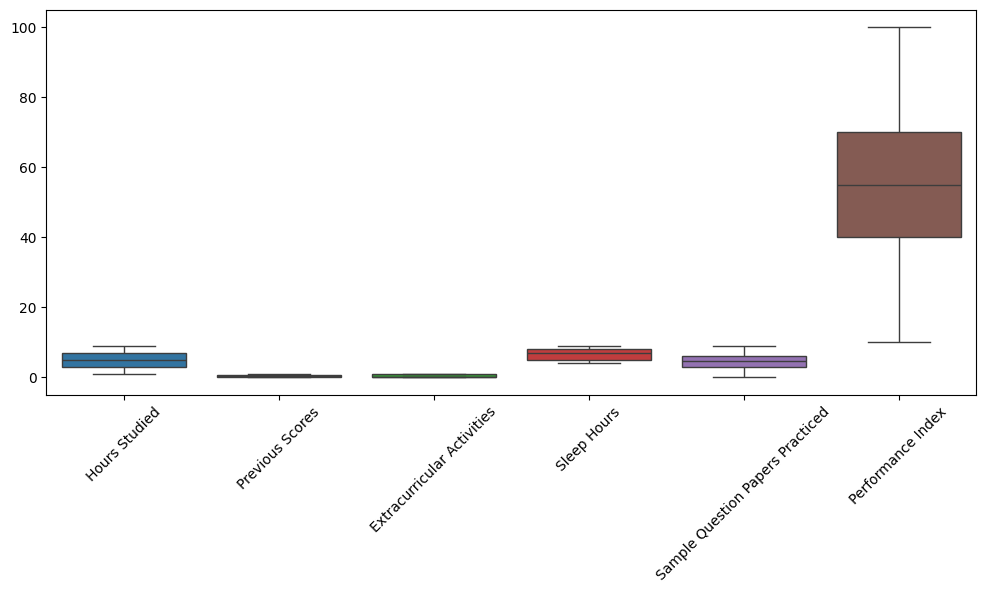

In [14]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=df.select_dtypes(include='number'))
plt.xticks(rotation=45)
plt.show()

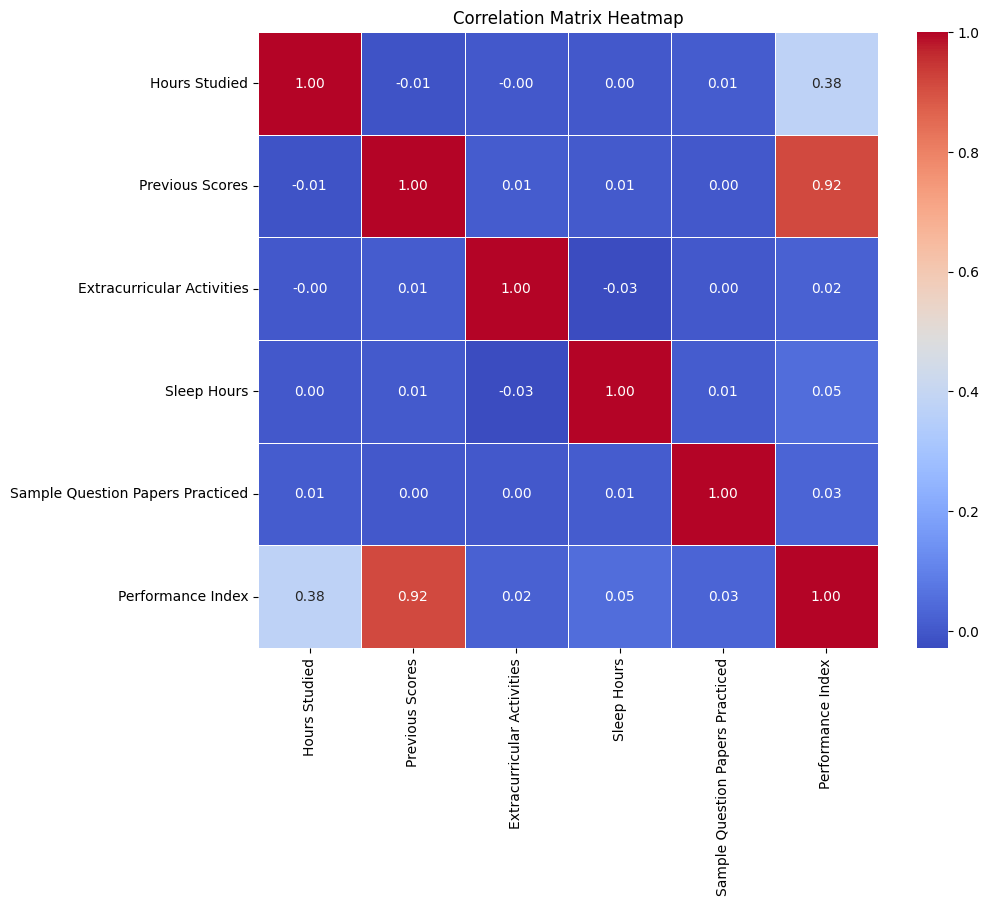

In [15]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix Heatmap')
plt.show()

In [16]:
X=df.drop(columns=['Performance Index'])
y=df['Performance Index']

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

X = df.drop(columns=['Performance Index'])
y = df['Performance Index']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=100
)

my_scaler = MinMaxScaler(feature_range=(0, 1))

X_train = my_scaler.fit_transform(X_train)

X_test = my_scaler.transform(X_test)



`%pip install -q xgboost lightgbm catboost`

In [22]:
%pip install -q xgboost lightgbm catboost

In [ ]:
from tqdm import tqdm

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor, BaggingRegressor,
                              AdaBoostRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor,
                              VotingRegressor, StackingRegressor)
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor


C:\Users\Ahmed\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\experimental\enable_hist_gradient_boosting.py:18: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


In [23]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor, BaggingRegressor,
                              AdaBoostRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor)
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "KNN": KNeighborsRegressor(n_neighbors=5, metric='minkowski', p=1),  # minkowski, euclidean, manhattan
    "SVM": SVR(kernel='linear', C=100, gamma=1),  # kernel='rbf' / 'poly', degree=4 / 'sigmoid'
    "Decision Tree": DecisionTreeRegressor(criterion='squared_error', max_depth=10),
    "Random Forest": RandomForestRegressor(n_estimators=50, criterion='squared_error', max_depth=10),
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error', max_depth=10),
                                n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
}

In [27]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Metrics function (same as the Ames notebook)
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

## 3) Train every model

In [28]:
from tqdm import tqdm

errors = {}
fitted_models = {}

for model_name, model in tqdm(models.items()):
    model.fit(X_train, y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)

    errors[model_name] = {
        "MAE Train": MAE_Train,
        "MAE Test": MAE_Test,
        "MSE Train": MSE_Train,
        "MSE Test": MSE_Test,
        "RMSE Train": RMSE_Train,
        "RMSE Test": RMSE_Test,
        "R2 Train": R_Train,
        "R2 Test": R_Test
    }
    fitted_models[model_name] = model

 93%|█████████▎| 14/15 [00:13<00:00,  1.83it/s]/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
100%|██████████| 15/15 [00:14<00:00,  1.06it/s]

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003231 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 88
[LightGBM] [Info] Number of data points in the train set: 7894, number of used features: 5
[LightGBM] [Info] Start training from score 55.334178


In [31]:
from sklearn.ensemble import StackingRegressor

# Base models for stacking
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# Meta-model
meta_regressor = XGBRegressor()

stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)

stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_Test, MSE_Test, RMSE_Test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)
errors["Stacking"] = {
    "MAE Train": MAE_Train,
    "MAE Test": MAE_Test,
    "MSE Train": MSE_Train,
    "MSE Test": MSE_Test,
    "RMSE Train": RMSE_Train,
    "RMSE Test": RMSE_Test,
    "R2 Train": R2_Train,
    "R2 Test": R2_Test
}
fitted_models["Stacking"] = stacking_regressor

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


## 4) Comparison table (all models)

In [ ]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test", ascending=False)
errors_df


,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
Linear Regression,1.638824,1.680140,4.248736,4.501355,2.061246,2.121640,0.988415,0.988147
Ridge,1.638869,1.680499,4.249499,4.501684,2.061431,2.121717,0.988413,0.988146
SVM,1.638697,1.681859,4.250097,4.509798,2.061576,2.123629,0.988412,0.988124
CatBoost,1.626883,1.698776,4.190016,4.643317,2.046953,2.154836,0.988576,0.987773
HistGradientBoosting,1.531112,1.717643,3.689252,4.763229,1.920743,2.182482,0.989941,0.987457
LightGBM,1.531112,1.717668,3.689252,4.764303,1.920743,2.182728,0.989941,0.987454
GradientBoosting,1.648821,1.719867,4.265230,4.827329,2.065243,2.197118,0.988370,0.987288
XGBoost,1.455375,1.735069,3.346032,4.871838,1.829216,2.207224,0.990877,0.987171
Stacking,1.623793,1.822932,4.350854,5.318443,2.085870,2.306175,0.988137,0.985995
Random Forest,1.317674,1.838783,2.714207,5.375089,1.647485,2.318424,0.992599,0.985846


## 5) Best model



In [34]:
import pandas as pd

# Ensure errors_df is defined even if the comparison cell wasn't run first
if 'errors_df' not in globals() and 'errors' in globals():
    errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test", ascending=False)

best_model_name = errors_df.index[0]
best_model = fitted_models[best_model_name]

print("=" * 65)
print(f"Best Model: {best_model_name}")
print("=" * 65)
print(f"{'Metric':<8}{'Train':>18}{'Test':>18}")
print("-" * 65)
for metric in ["MAE", "MSE", "RMSE", "R2"]:
    print(f"{metric:<8}"
          f"{errors_df.loc[best_model_name, metric + ' Train']:>18.4f}"
          f"{errors_df.loc[best_model_name, metric + ' Test']:>18.4f}")
print("=" * 65)

Best Model: Ridge
Metric               Train              Test
-----------------------------------------------------------------
MAE                 1.6375            1.6820
MSE                 4.2440            4.5043
RMSE                2.0601            2.1223
R2                  0.9885            0.9879


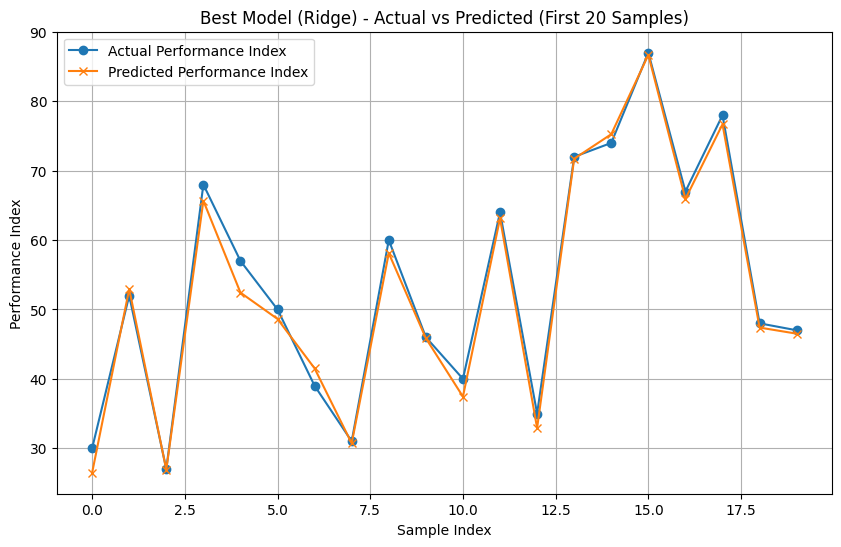

In [35]:
# Actual vs Predicted for the best model only (first 20 test samples)
y_test_plot = y_test.values[:20]
y_pred_plot = best_model.predict(X_test[:20])

plt.figure(figsize=(10, 6))
plt.plot(range(20), y_test_plot, label='Actual Performance Index', marker='o')
plt.plot(range(20), y_pred_plot, label='Predicted Performance Index', marker='x')
plt.xlabel('Sample Index')
plt.ylabel('Performance Index')
plt.title(f'Best Model ({best_model_name}) - Actual vs Predicted (First 20 Samples)')
plt.legend()
plt.grid()
plt.show()


## 6) Quick comparison charts

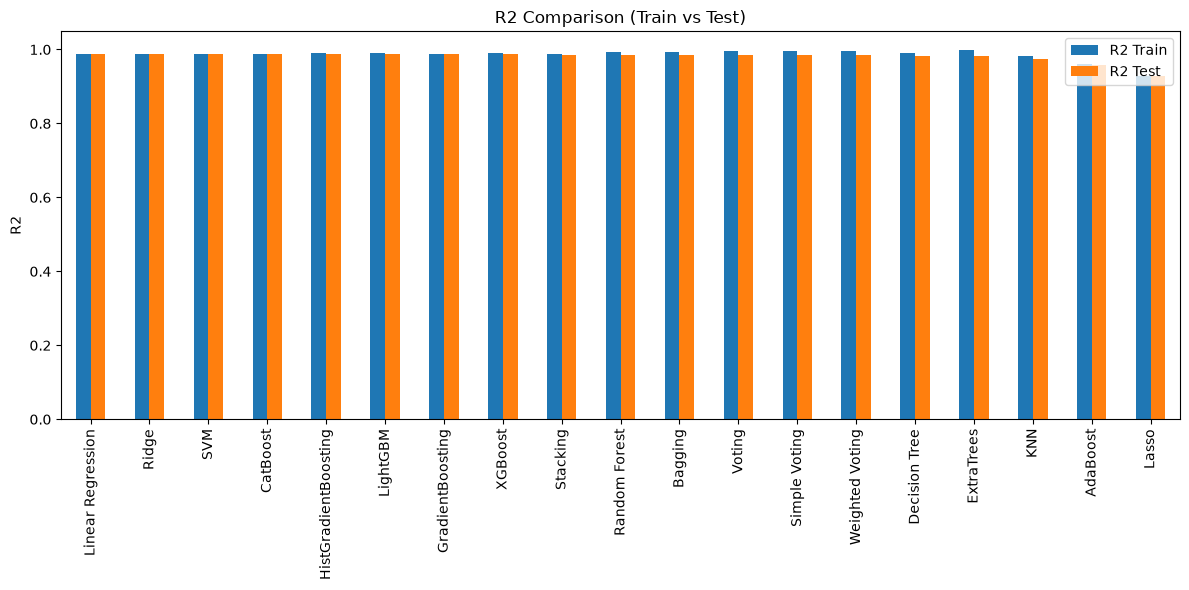

In [ ]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12, 6))
plt.title('R2 Comparison (Train vs Test)')
plt.ylabel('R2')
plt.tight_layout()
plt.show()


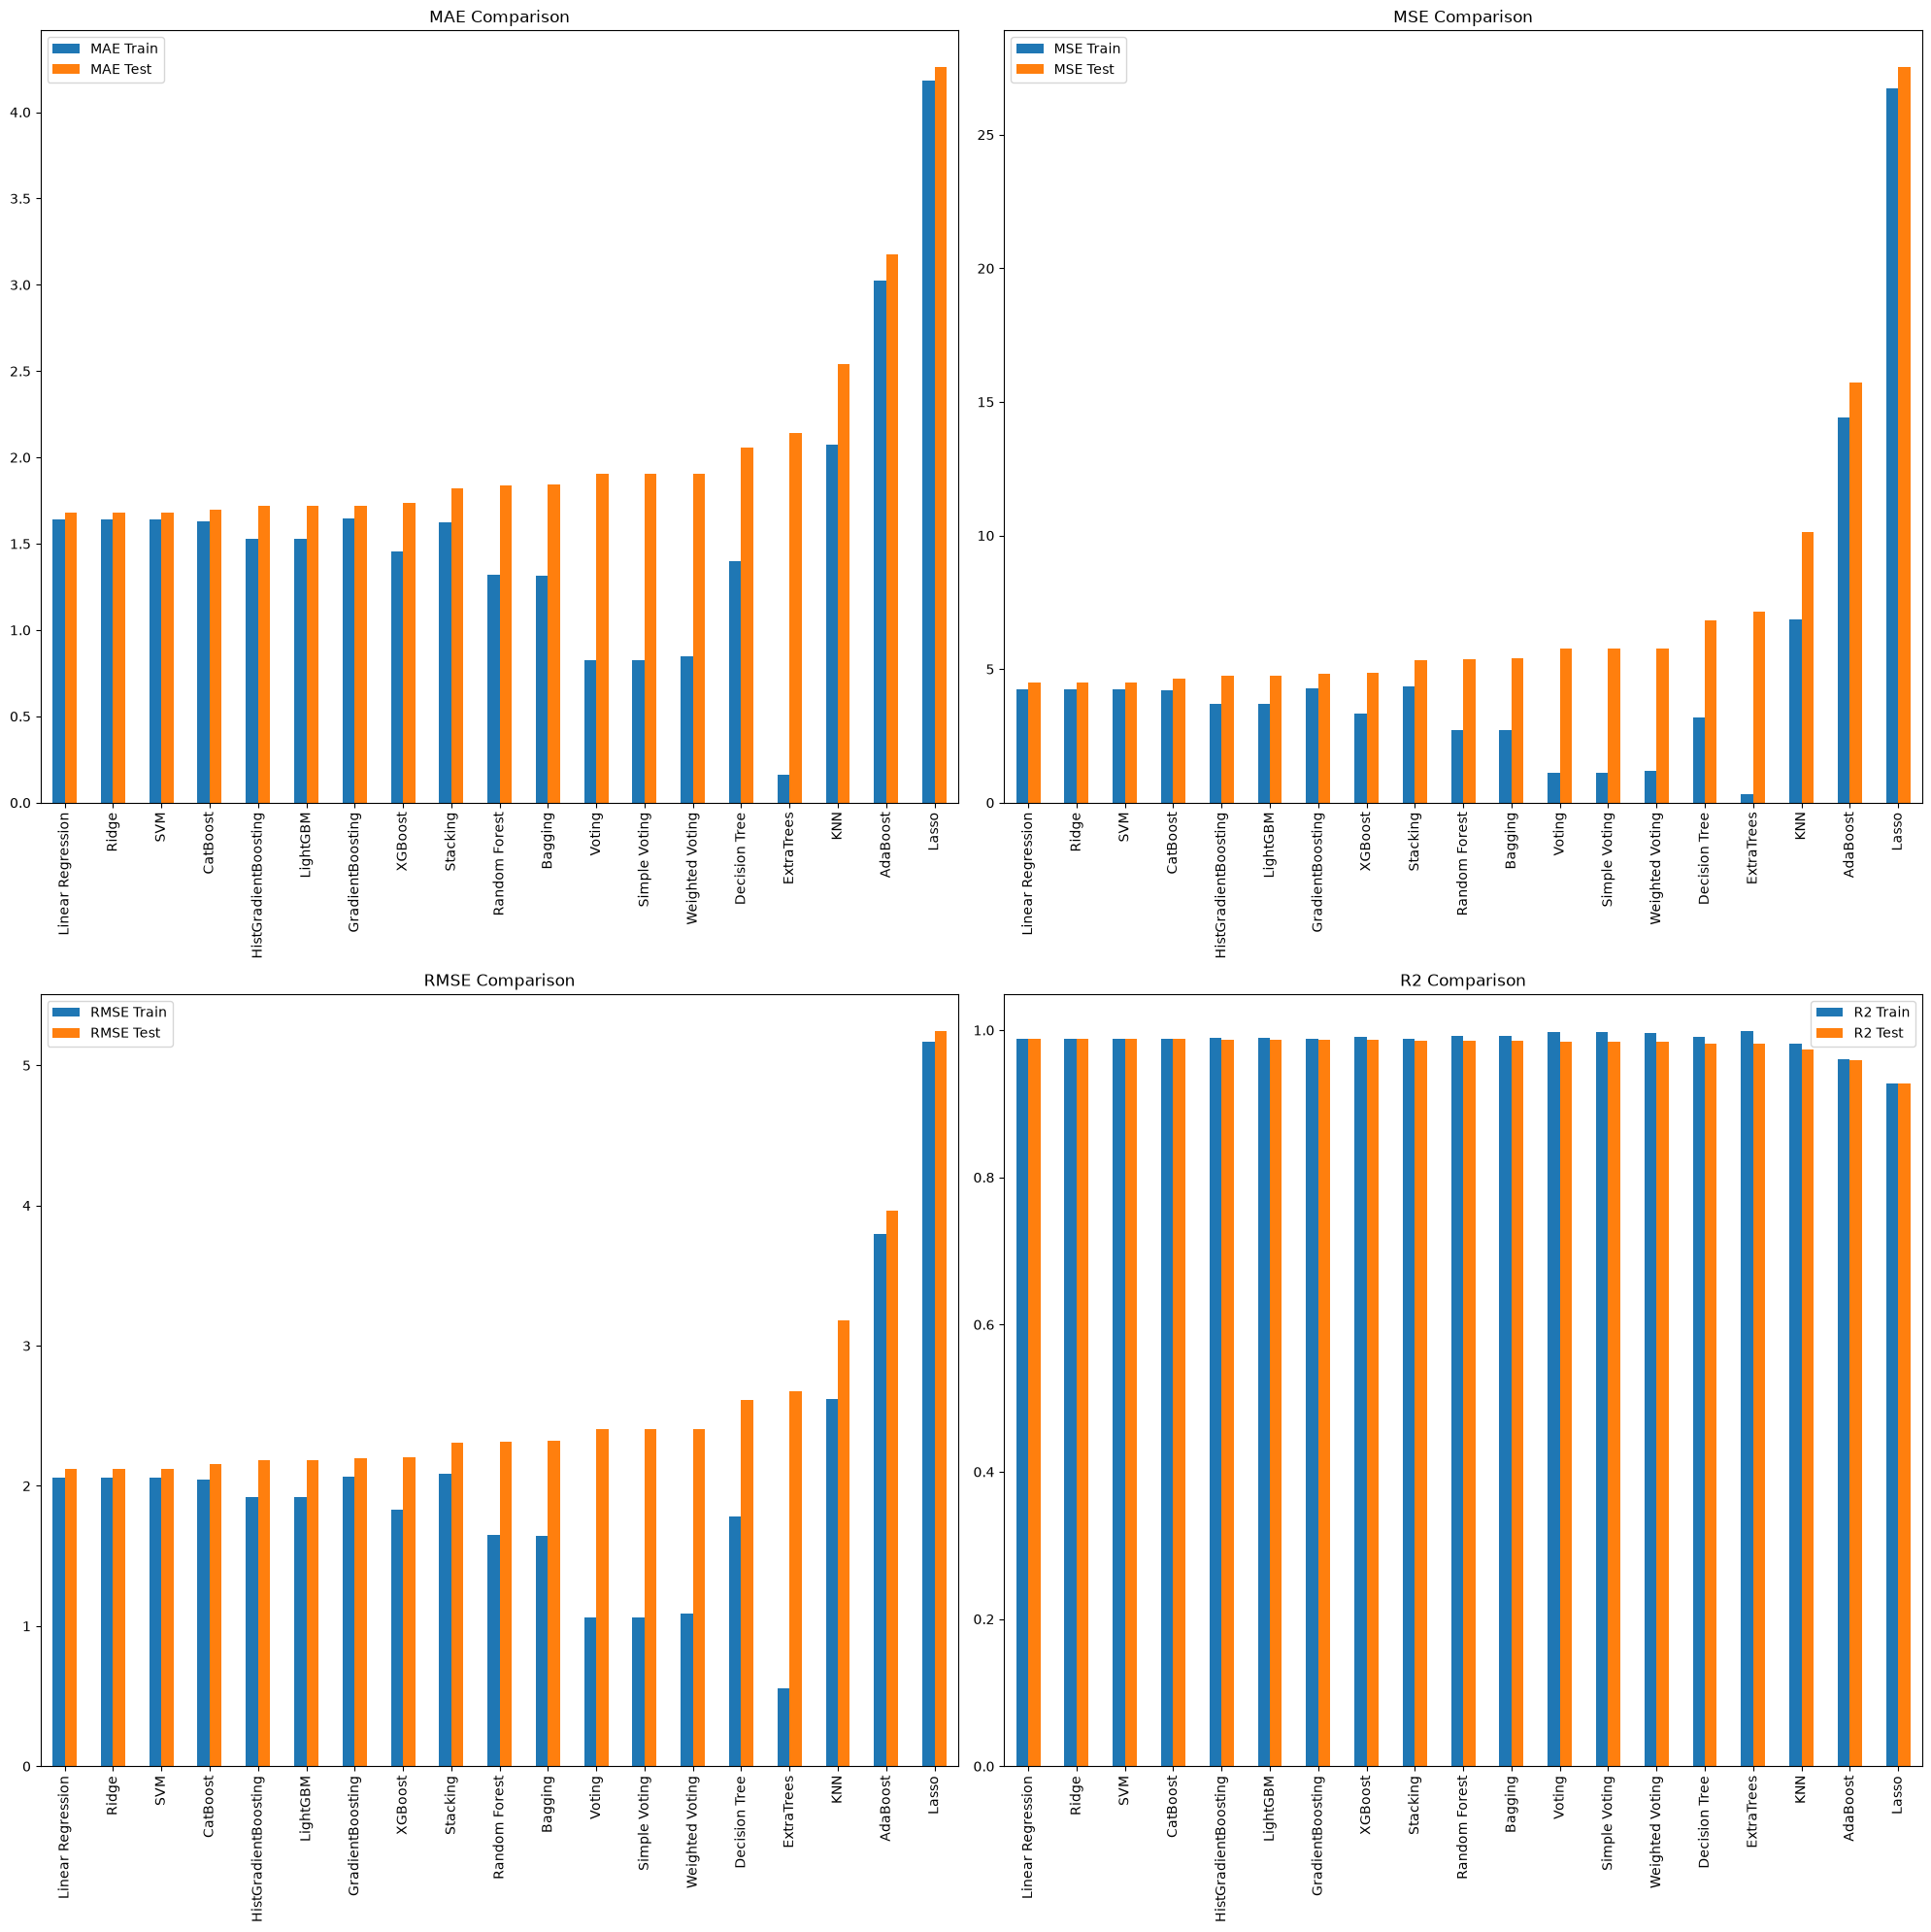

In [ ]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20, 20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i + 1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()


In [38]:

def predict_performance(hours_studied, previous_score, extracurricular, sleep_hours, sample_papers):

    input_data = pd.DataFrame([[
        hours_studied,
        previous_score,
        1 if extracurricular == "Yes" else 0,
        sleep_hours,
        sample_papers
    ]], columns=[
        'Hours Studied',
        'Previous Scores',
        'Extracurricular Activities',
        'Sleep Hours',
        'Sample Question Papers Practiced'
    ])

    input_scaled = my_scaler.transform(input_data)

    prediction = best_model.predict(input_scaled)[0]

    prediction = np.clip(prediction, 0, 100)

    return round(float(prediction), 2)


In [40]:

%pip install -q gradio

import gradio as gr
import numpy as np
import pandas as pd

# Get Best Model
best_model_name = errors_df.index[0]
best_model = fitted_models[best_model_name]


# Prediction Function
def predict_performance(
    hours_studied,
    previous_score,
    extracurricular,
    sleep_hours,
    sample_papers
):

    input_data = pd.DataFrame([[
        hours_studied,
        previous_score,
        1 if extracurricular == "Yes" else 0,
        sleep_hours,
        sample_papers
    ]], columns=[
        'Hours Studied',
        'Previous Scores',
        'Extracurricular Activities',
        'Sleep Hours',
        'Sample Question Papers Practiced'
    ])

    # Apply Scaling
    input_scaled = my_scaler.transform(input_data)

    # Predict
    prediction = best_model.predict(input_scaled)[0]

    # Keep Prediction Between 0 and 100
    prediction = np.clip(prediction, 0, 100)

    return round(float(prediction), 2)


# Input Components
inputs = [
    gr.Slider(1, 9, step=1, value=5, label="Hours Studied"),
    gr.Slider(40, 99, step=1, value=70, label="Previous Exam Score"),
    gr.Radio(["Yes", "No"], value="No", label="Extracurricular Activities"),
    gr.Slider(4, 9, step=1, value=6, label="Sleep Hours"),
    gr.Slider(0, 9, step=1, value=4, label="Sample Papers Practiced")
]

# Output
output = gr.Number(label="Predicted Performance Index")

# Gradio Interface
demo = gr.Interface(
    fn=predict_performance,
    inputs=inputs,
    outputs=output,
    title="Student Performance Predictor",
    description=f"""
    Predict student academic performance using Machine Learning.

    Best Model: **{best_model_name}**

    Test R2 Score: **0.9879**
    Test MAE: **1.6820**
    """
)

# Launch
demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ee49259e137253750c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
